In [1]:
import ast
import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from implicit.bpr import BayesianPersonalizedRanking
from implicit.als import AlternatingLeastSquares
from implicit.nearest_neighbours import CosineRecommender

# Reproducibility
SEED = 42
np.random.seed(SEED)

/Users/jeremysu/Downloads/cse158a2/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
DATA_PATH = "australian_users_items.json.gz"

rows = []
with gzip.open(DATA_PATH, "rt", encoding="utf-8") as f:
    for line in f:
        user_obj = ast.literal_eval(line)
        u_id = user_obj["user_id"]
        for item in user_obj["items"]:
            rows.append((
                u_id,
                item["item_id"],
                item["item_name"],
                item["playtime_forever"]
            ))

df_raw = pd.DataFrame(rows, columns=["user_id", "item_id", "item_name", "playtime_forever"])
df_raw = (
    df_raw.sort_values("playtime_forever", ascending=False)
    .drop_duplicates(subset=["user_id", "item_id"], keep="first")
)
item_names = df_raw.drop_duplicates("item_id").set_index("item_id")["item_name"].to_dict()

total_owned = len(df_raw)
zero_playtime = (df_raw["playtime_forever"] == 0).sum()

print(f"Total owned (user, game) pairs : {total_owned:,}")
print(f"Unique users                   : {df_raw['user_id'].nunique():,}")
print(f"Unique games                   : {df_raw['item_id'].nunique():,}")
print(f"Unplayed backlog (0 mins)      : {zero_playtime:,} ({zero_playtime / total_owned:.1%})")

Total owned (user, game) pairs : 5,094,082
Unique users                   : 70,912
Unique games                   : 10,978
Unplayed backlog (0 mins)      : 1,847,730 (36.3%)


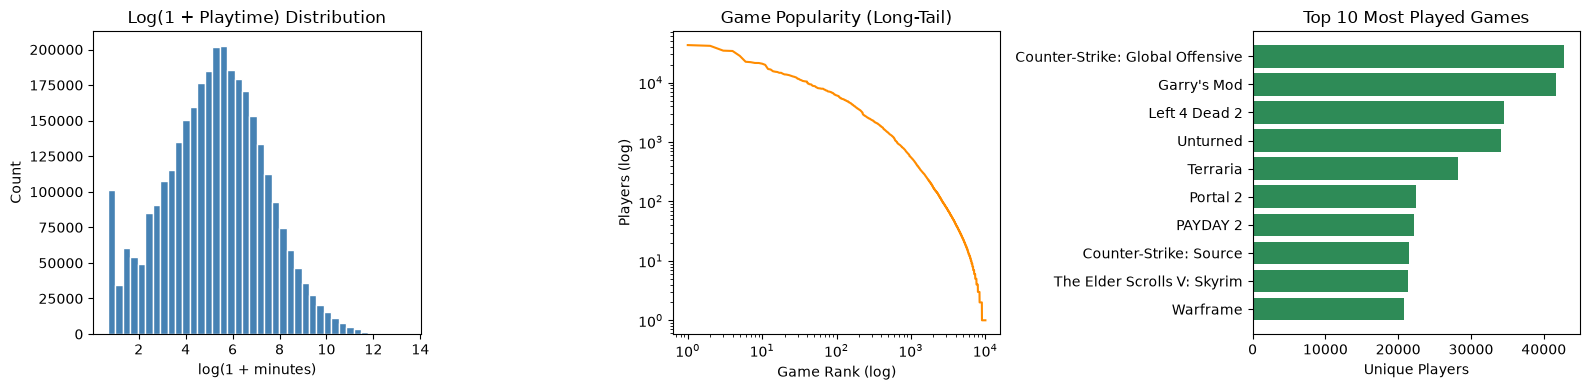

In [5]:
df_played = df_raw[df_raw["playtime_forever"] > 0].copy()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. Log-playtime distribution
axes[0].hist(np.log1p(df_played["playtime_forever"]), bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Log(1 + Playtime) Distribution")
axes[0].set_xlabel("log(1 + minutes)")
axes[0].set_ylabel("Count")

# 2. Item popularity long-tail (log-log)
item_counts = df_played["item_id"].value_counts().values
axes[1].loglog(range(1, len(item_counts) + 1), item_counts, color="darkorange")
axes[1].set_title("Game Popularity (Long-Tail)")
axes[1].set_xlabel("Game Rank (log)")
axes[1].set_ylabel("Players (log)")

# 3. Top 10 most played games
top_games = df_played["item_name"].value_counts().head(10)[::-1]
axes[2].barh(top_games.index, top_games.values, color="seagreen")
axes[2].set_title("Top 10 Most Played Games")
axes[2].set_xlabel("Unique Players")

plt.tight_layout()
plt.show()

In [6]:
def k_core_filter(df, min_user=5, min_item=5):
    df = df.copy()
    while True:
        u_counts = df["user_id"].value_counts()
        i_counts = df["item_id"].value_counts()
        valid_u = u_counts[u_counts >= min_user].index
        valid_i = i_counts[i_counts >= min_item].index
        new_df = df[df["user_id"].isin(valid_u) & df["item_id"].isin(valid_i)]
        if len(new_df) == len(df):
            return new_df
        df = new_df

df_clean = k_core_filter(df_played, min_user=5, min_item=5)

# Map IDs to contiguous integers
user2idx = {u: idx for idx, u in enumerate(df_clean["user_id"].unique())}
item2idx = {i: idx for idx, i in enumerate(df_clean["item_id"].unique())}
idx2item = {idx: i for i, idx in item2idx.items()}

df_clean["u_idx"] = df_clean["user_id"].map(user2idx)
df_clean["i_idx"] = df_clean["item_id"].map(item2idx)

n_users = len(user2idx)
n_items = len(item2idx)
print(f"After 5-core filtering: {n_users:,} users, {n_items:,} games, {len(df_clean):,} interactions")
print(f"Matrix sparsity: {1 - len(df_clean) / (n_users * n_items):.4%}")

# Leave-One-Out split per user (1 Val, 1 Test, rest Train)
df_shuffled = df_clean.sample(frac=1, random_state=SEED)
df_shuffled["rank"] = df_shuffled.groupby("u_idx").cumcount()

test_df  = df_shuffled[df_shuffled["rank"] == 0]
val_df   = df_shuffled[df_shuffled["rank"] == 1]
train_df = df_shuffled[df_shuffled["rank"] >= 2]

# Build sparse User x Item matrices
# 1. Binary matrix (for Popularity, Cosine, BPR, Binary ALS)
train_binary = csr_matrix(
    (np.ones(len(train_df), dtype=np.float32), (train_df["u_idx"], train_df["i_idx"])),
    shape=(n_users, n_items)
)

# 2. Playtime-weighted matrix: c_ui = 1 + alpha * log(1 + playtime)
ALPHA = 2.0
weights = 1.0 + ALPHA * np.log1p(train_df["playtime_forever"].values).astype(np.float32)
train_weighted = csr_matrix(
    (weights, (train_df["u_idx"], train_df["i_idx"])),
    shape=(n_users, n_items)
)

After 5-core filtering: 59,746 users, 7,603 games, 3,221,831 interactions
Matrix sparsity: 99.2907%


In [7]:
# Build user -> set of all played items (to avoid sampling true positives as negatives)
user_all_items = df_clean.groupby("u_idx")["i_idx"].apply(set).to_dict()

def build_eval_candidates(eval_df, n_neg=99, max_users=5000):
    """Pre-sample 99 negatives per user so every model is evaluated on the exact same candidates."""
    sample_df = eval_df.sample(n=min(max_users, len(eval_df)), random_state=SEED)
    candidates = {}
    for u, pos_i in zip(sample_df["u_idx"], sample_df["i_idx"]):
        seen = user_all_items[u]
        negs = []
        while len(negs) < n_neg:
            cand = np.random.randint(0, n_items)
            if cand not in seen:
                negs.append(cand)
        # Index 0 is always the ground-truth positive item
        candidates[u] = np.array([pos_i] + negs, dtype=np.int32)
    return candidates

val_candidates  = build_eval_candidates(val_df,  n_neg=99, max_users=5000)
test_candidates = build_eval_candidates(test_df, n_neg=99, max_users=5000)

def evaluate_ranking(score_fn, candidates, k=10):
    hits, ndcgs = [], []
    for u, items in candidates.items():
        scores = score_fn(u, items)
        # Rank of the true positive (which is at position 0 in `items`)
        rank = (scores > scores[0]).sum()
        if rank < k:
            hits.append(1.0)
            ndcgs.append(1.0 / np.log2(rank + 2))
        else:
            hits.append(0.0)
            ndcgs.append(0.0)
    return np.mean(hits), np.mean(ndcgs)

In [10]:
results = []

# 1. Most Popular Baseline
item_pop = np.asarray(train_binary.sum(axis=0)).ravel()
pop_hr, pop_ndcg = evaluate_ranking(lambda u, items: item_pop[items], test_candidates)
results.append({"Model": "Most Popular", "Test HR@10": pop_hr, "Test NDCG@10": pop_ndcg})

# 2. Item-Item Jaccard (Course Baseline) ---
item_deg = np.asarray(train_binary.sum(axis=0)).ravel().astype(np.float32)
cooc = (train_binary.T @ train_binary).tocsr()

def score_jaccard(u, items):
    u_items = train_binary[u].indices
    if len(u_items) == 0:
        return np.zeros(len(items), dtype=np.float32)
    inter = cooc[u_items][:, items].toarray().astype(np.float32)
    union = item_deg[u_items][:, None] + item_deg[items][None, :] - inter
    jacc = np.divide(inter, union, out=np.zeros_like(inter), where=union > 0)
    return jacc.sum(axis=0)

jacc_hr, jacc_ndcg = evaluate_ranking(score_jaccard, test_candidates)
results.append({"Model": "Item-Item Jaccard", "Test HR@10": jacc_hr, "Test NDCG@10": jacc_ndcg})

# 3. Item-Item Cosine Similarity (Course Baseline)
cos_model = CosineRecommender(K=50)
cos_model.fit(train_binary)

def score_cosine(u, items):
    # Compute dot product between user's train vector and candidate item similarity columns
    user_vec = train_binary[u]
    return np.asarray(user_vec.dot(cos_model.similarity[:, items]).toarray()).ravel()

cos_hr, cos_ndcg = evaluate_ranking(score_cosine, test_candidates)
results.append({"Model": "Item-Item Cosine", "Test HR@10": cos_hr, "Test NDCG@10": cos_ndcg})

# 4. BPR (Bayesian Personalized Ranking)
bpr_model = BayesianPersonalizedRanking(factors=64, regularization=0.01, iterations=100, random_state=SEED)
bpr_model.fit(train_binary)

def score_mf(model):
    return lambda u, items: model.item_factors[items] @ model.user_factors[u]

bpr_hr, bpr_ndcg = evaluate_ranking(score_mf(bpr_model), test_candidates)
results.append({"Model": "BPR (Binary)", "Test HR@10": bpr_hr, "Test NDCG@10": bpr_ndcg})

# 5. Binary ALS (Ablation Baseline)
als_bin = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=20, random_state=SEED)
als_bin.fit(train_binary)
als_b_hr, als_b_ndcg = evaluate_ranking(score_mf(als_bin), test_candidates)
results.append({"Model": "ALS (Binary)", "Test HR@10": als_b_hr, "Test NDCG@10": als_b_ndcg})

# 6. Playtime-Weighted ALS (Main Model)
als_wt = AlternatingLeastSquares(factors=64, regularization=0.1, iterations=20, random_state=SEED)
als_wt.fit(train_weighted)
als_w_hr, als_w_ndcg = evaluate_ranking(score_mf(als_wt), test_candidates)
results.append({"Model": "ALS (Log-Playtime Weighted)", "Test HR@10": als_w_hr, "Test NDCG@10": als_w_ndcg})

results_df = pd.DataFrame(results)
display(results_df.round(4))

/Users/jeremysu/Downloads/cse158a2/.venv/lib/python3.14/site-packages/implicit/utils.py:164: ParameterWarning: Method expects CSR input, and was passed coo_matrix instead. Converting to CSR took 0.021173954010009766 seconds
  warnings.warn(
100%|██████████| 20/20 [00:17<00:00,  1.11it/s]


,Model,Test HR@10,Test NDCG@10
0,Most Popular,0.8528,0.6107
1,Item-Item Jaccard,0.8840,0.6613
2,Item-Item Cosine,0.9554,0.7168
3,BPR (Binary),0.7762,0.5547
4,ALS (Binary),0.7710,0.5556
5,ALS (Log-Playtime Weighted),0.8826,0.6911


In [11]:
def inspect_user(u_idx, model, top_n=5):
    # User's top played games in training set
    u_train = train_df[train_df["u_idx"] == u_idx].sort_values("playtime_forever", ascending=False)
    print(f"=== User {u_idx} | Top Played Games (Train) ===")
    for _, row in u_train.head(5).iterrows():
        print(f"  - {row['item_name']} ({row['playtime_forever'] / 60:.1f} hrs)")

    # Ground-truth held-out test game
    test_item = test_df[test_df["u_idx"] == u_idx]["item_id"].values[0]
    print(f"\nHeld-out Test Game: {item_names[test_item]}")

    # Model's top-N recommendations (excluding training items)
    rec_ids, rec_scores = model.recommend(u_idx, train_binary[u_idx], N=top_n, filter_already_liked_items=True)
    print(f"\nTop-{top_n} Recommended Games:")
    for rank, (i_idx, score) in enumerate(zip(rec_ids, rec_scores), 1):
        name = item_names[idx2item[i_idx]]
        hit_tag = "  <-- HIT!" if idx2item[i_idx] == test_item else ""
        print(f"  {rank}. {name} (score: {score:.3f}){hit_tag}")

# Inspect a couple of sample users
inspect_user(u_idx=10, model=als_wt, top_n=5)

=== User 10 | Top Played Games (Train) ===
  - Garry's Mod (8213.5 hrs)
  - ARK: Survival Evolved (490.9 hrs)
  - Grand Theft Auto V (399.6 hrs)
  - METAL GEAR SOLID V: THE PHANTOM PAIN (339.0 hrs)
  - The Witcher 3: Wild Hunt (238.6 hrs)

Held-out Test Game: PlanetSide 2

Top-5 Recommended Games:
  1. Evolve Stage 2 (score: 1.231)
  2. Contagion (score: 1.216)
  3. Half-Life 2: Deathmatch (score: 1.092)
  4. Cry of Fear (score: 1.025)
  5. Dead Space (score: 1.023)
